**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**13 | Matched Subject-Level Cross-Validation: RF vs Two CNN Losses**

![Stage 13 scientific workflow](../../images/13_workflow.svg)

**Objective:** Compare Random Forest, a standard CNN and a class-weighted CNN across three participant-disjoint Development folds using matched HARTH source windows.

**Dataset:** The bounded 14,201-window HARTH v2.0 cohort from 29 Development participants, excluding reserved Test IDs S023 and S032.

**Notebook Scope:** Audit activity support, refit each model within the same three GroupKFold splits and compare fold, class and participant-level results. These folds provide exploratory Development evidence, not independent replications or a final Test benchmark.

**00. Colab Repository Setup**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# ------------------------- Repository Configuration --------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

# ------------------------ Clone Repository if Missing ------------------------
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ------------------------------ Open Repository ------------------------------
%cd {repo_path}


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ---------------------- Study Environment Configuration ----------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------------------- Standard Library ------------------------------
import sys
from pathlib import Path

# ---------------------- Data Analysis and Visualisation ----------------------
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

# ------------------------- Deep Learning and Display -------------------------
import torch

# ------------------------- Repository Configuration --------------------------
from IPython.display import display

root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root == root.parent: raise RuntimeError("Open this notebook inside the repository.")
    root = root.parent

# ------------------- HARTH Cohort and Activity Definitions -------------------
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# -------------------- Grouped Model Comparison Utilities ---------------------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, SENSOR_COLUMNS, prepare_harth_window_cohort

# -------------------------------- Plot Style ---------------------------------
from core.temporal_comparison import compare_models_group_cv
from core.group_cross_validation import compare_models_by_subject

# ------------------------- Training Device Selection -------------------------
from core.plot_style import plot_style
plot_style()

from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type

print("Repository root:", root)
print("Training compute device:", DEVICE)


Compute device and system information
OS: Linux 6.6.122+
CPU: x86_64
Installed RAM: 12.7 GiB
nvidia-smi is not available in this environment.
PyTorch version: 2.11.0+cpu
CUDA is not available to PyTorch; using CPU.
Selected compute device: cpu
Repository root: /content/human-movement-intelligence
Training compute device: cpu


**02. Reconstruct the Matched Development Window Cohort**

Reuse the label-pure 100-sample windows and 500-window-per-participant cap from Notebooks 10–12. All three models use the same 14,201 source windows; reserved Test participants are excluded before loading.

In [3]:
# ================ 02. Build the Matched Bounded Source Cohort ================

# ------------------- Reserved Test and Development Cohort --------------------
RESERVED_TEST = {"S023", "S032"}

DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ------------------- Task Definition and Bounded Sampling --------------------
TASK_CLASSES = tuple(range(1, 9))

X, y, metadata, overview = prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES, max_windows_per_subject=500,
    window_size=100, step_size=50, sampling_rate=50,
)

# ----------------------------- Cohort Integrity ------------------------------
assert len(DEVELOPMENT_SUBJECTS) == len(set(DEVELOPMENT_SUBJECTS)) == 29
assert not (set(metadata["subject_id"]) & RESERVED_TEST)

# ------------------- Source Window and Participant Summary -------------------
print("Shared signal cohort:", X.shape)

display(overview[["subject_id", "eligible_windows", "sampled_windows"]])


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)
Shared signal cohort: (14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


**03. Inspect Participant-Level Activity Support**

Summarise the eight documented activity classes by participant before model fitting. GroupKFold separates participants but does not equalise class prevalence between folds.

In [4]:
# ================= 03. Inspect Activity Coverage by Subject ==================

# ---------------------- Activity Support by Participant ----------------------
coverage = pd.crosstab(metadata["subject_id"], metadata["label"]).reindex(
    index=DEVELOPMENT_SUBJECTS, columns=TASK_CLASSES, fill_value=0
)

# -------------------------- Documented Class Names ---------------------------
coverage.columns = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]

# --------------------- Coverage and Independent Support ----------------------
display(coverage)

print("Independent participants supporting each class:",
      (coverage > 0).sum(axis=0).to_dict())


,1: Walking,2: Running,3: Shuffling,4: Stairs ascending,5: Stairs descending,6: Standing,7: Sitting,8: Lying
subject_id,,,,,,,,
S006,17,0,4,2,3,80,375,19
S008,20,0,22,0,1,65,392,0
S009,91,0,0,7,9,94,0,0
S010,270,0,18,8,3,125,76,0
S012,13,2,3,5,2,24,426,25
S013,41,5,35,4,1,56,348,10
S014,20,4,10,7,3,68,373,15
S015,65,3,2,6,5,78,257,84
S016,57,3,10,0,2,66,301,61


Independent participants supporting each class: {'1: Walking': 29, '2: Running': 19, '3: Shuffling': 26, '4: Stairs ascending': 24, '5: Stairs descending': 25, '6: Standing': 29, '7: Sitting': 28, '8: Lying': 23}


**04. Fit Three Models Across Matched GroupKFold Splits**

Refit Random Forest, standard CNN and weighted CNN in each of three subject-disjoint folds. Derive Random Forest features from the shared windows; estimate CNN scaling and class weights using fold Train data only. The bounded CPU experiment uses five epochs per CNN fit.

In [5]:
# ================== 04. Run Three-Model Matched GroupKFold ===================

# ------------------ Grouped Evaluation and Training Budget -------------------
FOLDS = 3

EPOCHS = 5

# ------------------------------ Training Device ------------------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------- Matched Three-Model GroupKFold -----------------------
fold_results, subject_results, class_results, prediction_records = compare_models_group_cv(
    windows=X,
    labels=y,
    subject_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    channel_names=SENSOR_COLUMNS,
    n_splits=FOLDS,
    epochs=EPOCHS,
    batch_size=128,
    learning_rate=1e-3,
    random_state=42,
    device=DEVICE,
    forbidden_subject_ids=RESERVED_TEST,  # Exclude reserved Test participants from the evaluation.
)

# ----------------------- Fold-Level Validation Results -----------------------
display(fold_results[[
    "fold", "model", "validation_subjects", "train_windows",
    "validation_windows", "validation_classes_present",
    "macro_f1", "balanced_accuracy"
]].round(4))


Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Fold 1/3: fitting Standard CNN
Epoch 1/5 | loss=0.8096 | validation Macro F1=0.5744
Epoch 2/5 | loss=0.3466 | validation Macro F1=0.5847
Epoch 3/5 | loss=0.2615 | validation Macro F1=0.5871
Epoch 4/5 | loss=0.2131 | validation Macro F1=0.5894
Epoch 5/5 | loss=0.1872 | validation Macro F1=0.6311
Fold 1/3: fitting Weighted CNN
Epoch 1/5 | loss=1.0101 | validation Macro F1=0.5767
Epoch 2/5 | loss=0.5557 | validation Macro F1=0.6125
Epoch 3/5 | loss=0.4243 | validation Macro F1=0.7226
Epoch 4/5 | loss=0.3267 | validation Macro F1=0.7492
Epoch 5/5 | loss=0.2661 | validation Macro F1=0.7265
Fold 1: 19 Train subjects, 10 held-out subjects
Fold 2/3: fitting Standard CNN
Epoch 1/5 | loss=0.7609 | validation Macro F1=0.5946
Epoch 2/5 | loss=0.3078 | validation Macro F1=0.5953
Epoch 3/5 | loss=0.2400 | validation Macro F1=0.6011
Epoch 4/5 | loss=0.2016 | validation Macro F1=0.6120
E

,fold,model,validation_subjects,train_windows,validation_windows,validation_classes_present,macro_f1,balanced_accuracy
0,1,Random Forest,"S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,8,0.7969,0.8368
1,1,Standard CNN,"S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,8,0.6311,0.6261
2,1,Weighted CNN,"S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,8,0.7265,0.8176
3,2,Random Forest,"S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,8,0.7669,0.7608
4,2,Standard CNN,"S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,8,0.6654,0.6481
5,2,Weighted CNN,"S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,8,0.7938,0.7782
6,3,Random Forest,"S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,8,0.8645,0.8213
7,3,Standard CNN,"S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,8,0.5936,0.6063
8,3,Weighted CNN,"S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,8,0.8261,0.8158


**05. Compare Fold-Level Macro F1**

Recorded three-fold mean Macro F1 was 0.8076 for Random Forest, 0.6301 for standard CNN and 0.7834 for weighted CNN. These are correlated Development-fold summaries; differences alone do not establish statistical superiority.

,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean
0,Random Forest,0.8094,0.0500,0.8063
1,Standard CNN,0.6300,0.0359,0.6268
2,Weighted CNN,0.7821,0.0508,0.8038


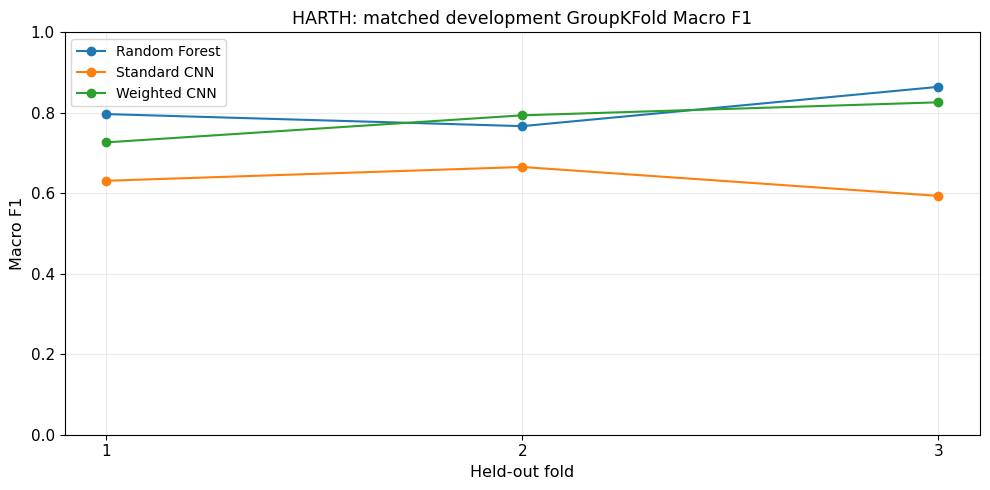

In [6]:
# ================ 05. Visualise Held-Out Fold Score Variation ================

# ---------------------------- Fold Score Summary -----------------------------
fold_summary = fold_results.groupby("model", as_index=False).agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_sd=("macro_f1", "std"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
)

display(fold_summary.round(4))

# ------------------------- Held-Out Macro F1 Curves --------------------------
fig, ax = plt.subplots(figsize=(10, 5))

for name, table in fold_results.groupby("model", sort=False):
    table = table.sort_values("fold")
    ax.plot(table["fold"], table["macro_f1"], marker="o", label=name)

ax.set(title="HARTH: matched development GroupKFold Macro F1",
       xlabel="Held-out fold", ylabel="Macro F1", ylim=(0, 1),
       xticks=list(range(1, FOLDS + 1)))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


**06. Inspect Pooled Out-of-Fold Class Errors**

Each selected window receives one held-out prediction per model across the three folds. Compare pooled class-specific scores while recognising that overlapping windows are not independent participants.

,model,activity,support,precision,recall,f1
0,Random Forest,Walking,3591,0.9272,0.9510,0.9390
1,Random Forest,Running,1028,0.9836,0.9903,0.9869
2,Random Forest,Shuffling,219,0.4756,0.5342,0.5032
3,Random Forest,Stairs ascending,192,0.7310,0.5521,0.6291
4,Random Forest,Stairs descending,182,0.7031,0.4945,0.5806
5,Random Forest,Standing,2227,0.9382,0.9618,0.9499
6,Random Forest,Sitting,5599,0.9969,0.9791,0.9879
7,Random Forest,Lying,1163,0.9831,0.9991,0.9910
8,Standard CNN,Walking,3591,0.8883,0.9496,0.9179
9,Standard CNN,Running,1028,0.9835,0.9864,0.9849


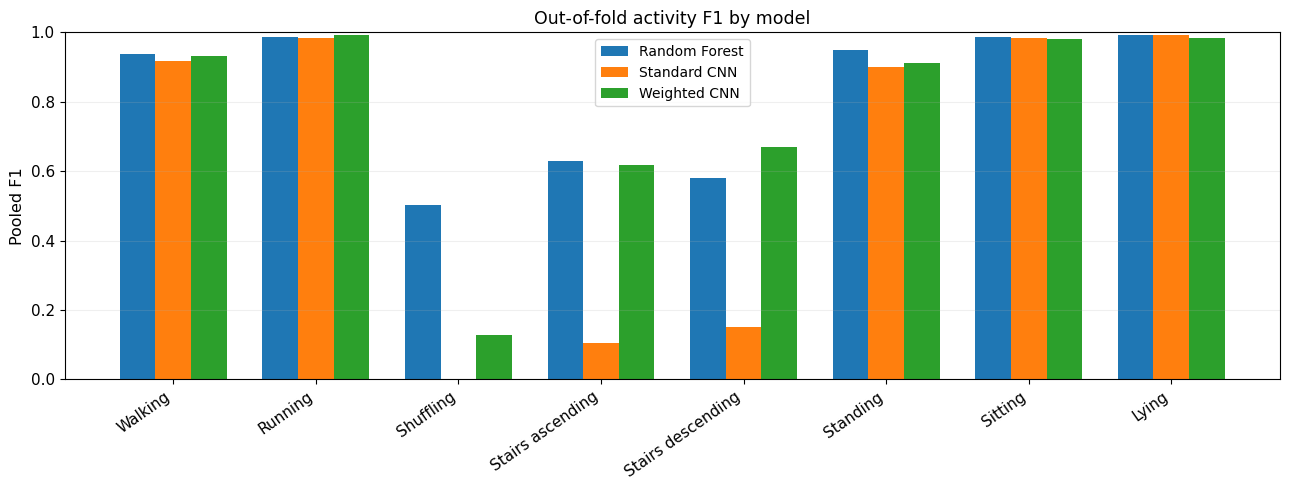

In [7]:
# ================== 06. Inspect Pooled Out-of-Fold Class F1 ==================

# ----------------- Source Activity Mapping and Class Metrics -----------------
class_results["activity"] = class_results["class"].map(
    lambda code: ACTIVITY_NAMES[int(code)]
)

display(class_results[[
    "model", "activity", "support", "precision", "recall", "f1"
]].round(4))

# ------------------------- Class-Level F1 Comparison -------------------------
fig, ax = plt.subplots(figsize=(13, 5))

# -------------------------- Matched Model Ordering ---------------------------
names = ["Random Forest", "Standard CNN", "Weighted CNN"]
positions = np.arange(len(TASK_CLASSES))
bar_width = 0.25

for i, name in enumerate(names):
    values = class_results.loc[class_results["model"] == name, "f1"].to_numpy()
    ax.bar(positions + (i-1)*bar_width, values, width=bar_width, label=name)
ax.set_xticks(positions, [ACTIVITY_NAMES[c] for c in TASK_CLASSES],
              rotation=35, ha="right")

ax.set(title="Out-of-fold activity F1 by model",
       ylabel="Pooled F1", ylim=(0, 1))
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()


**07. Compare Paired Participant-Level Macro F1**

Use fixed eight-class Macro F1 to compare the same 29 held-out participants, and report class support separately. Weighted CNN exceeded standard CNN for 27 of 29 participants. Against Random Forest it scored higher for 14 and lower for 15; these counts are descriptive.

,fold,model,subject_id,windows,observed_classes,macro_f1_fixed_task
0,1,Random Forest,S006,500,7,0.6826
10,1,Standard CNN,S006,500,7,0.4598
20,1,Weighted CNN,S006,500,7,0.6218
60,3,Random Forest,S008,500,5,0.4254
69,3,Standard CNN,S008,500,5,0.3355
...,...,...,...,...,...,...
49,2,Standard CNN,S037,500,7,0.6948
59,2,Weighted CNN,S037,500,7,0.8314
9,1,Random Forest,S038,500,8,0.8608
19,1,Standard CNN,S038,500,8,0.6175


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN,Standard CNN,macro_f1_fixed_task,29,0.137,0.147,27,2,0


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN,Random Forest,macro_f1_fixed_task,29,-0.0094,-0.0112,14,15,0


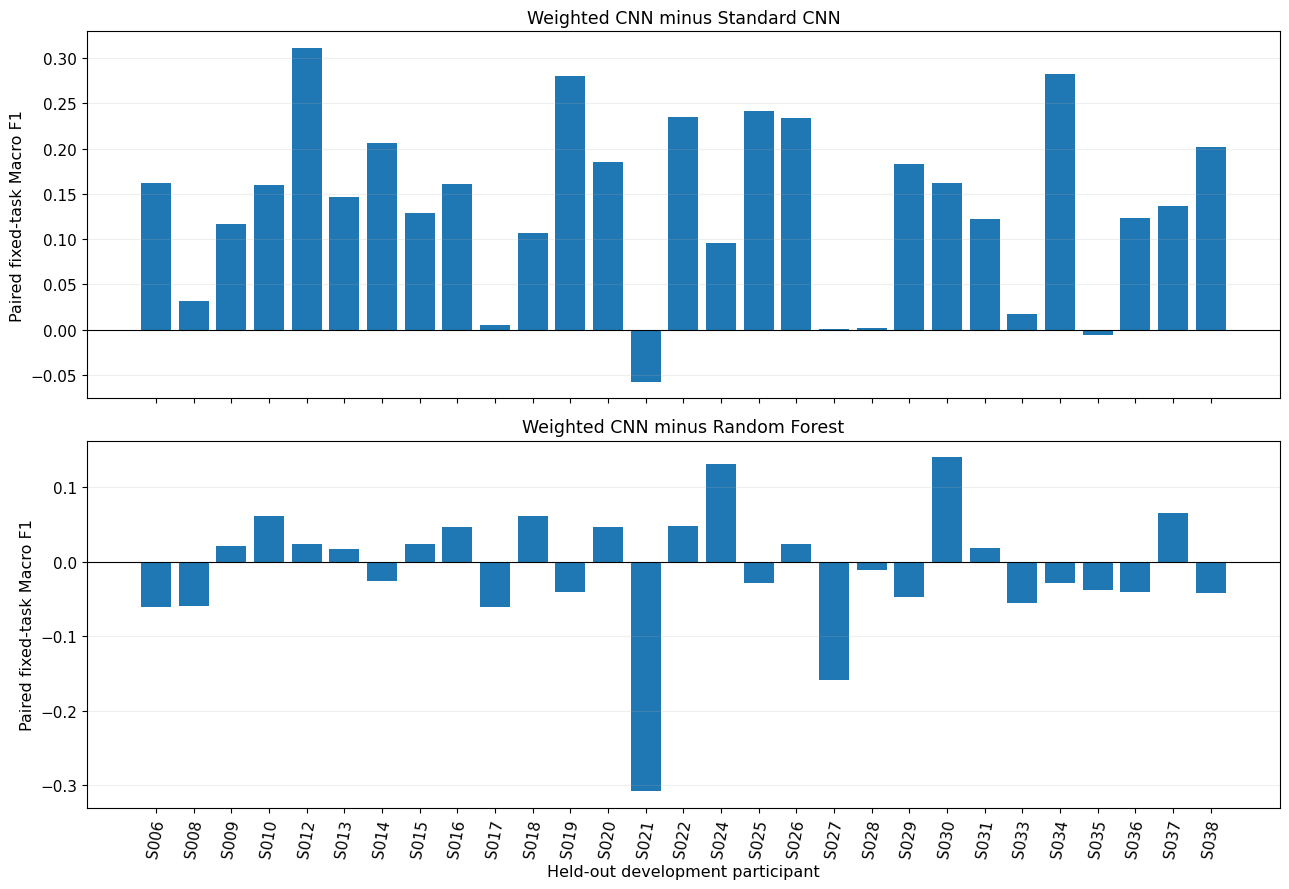

In [8]:
# ================ 07. Compare Paired Per-Person Validation F1 ================

# ------------------- Fixed Eight-Class Participant Scores --------------------
display(subject_results[[
    "fold", "model", "subject_id", "windows",
    "observed_classes", "macro_f1_fixed_task"
]].sort_values(["subject_id", "model"]).round(4))

# ------------------------- Paired Model Comparisons --------------------------
comparisons = [
    ("Weighted CNN", "Standard CNN"),
    ("Weighted CNN", "Random Forest"),
]

# --------------------- Held-Out Participant Differences ----------------------
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for ax, (model_a, model_b) in zip(axes, comparisons):
    paired, pair_summary = compare_models_by_subject(
        subject_results, model_a=model_a, model_b=model_b,
        score_column="macro_f1_fixed_task",
    )
    display(pd.DataFrame([pair_summary]).round(4))
    ax.bar(paired["subject_id"], paired["difference_a_minus_b"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=f"{model_a} minus {model_b}",
           ylabel="Paired fixed-task Macro F1")
    ax.grid(axis="y", alpha=0.2)

axes[-1].tick_params(axis="x", rotation=80)
axes[-1].set_xlabel("Held-out development participant")
fig.tight_layout()
plt.show()


**08. Scientific Quality Gate and Evidence Limits**

Verify source-row alignment, participant separation and complete out-of-fold coverage for all three models. The results describe matched Development cross-validation and do not replace independent Test evaluation.

In [9]:
# =============== 08. Research Quality Gate and Evidence Limits ===============

# ------------------- Development and Test Cohort Integrity -------------------
assert set(subject_results["subject_id"]) == set(DEVELOPMENT_SUBJECTS)

assert not (set(subject_results["subject_id"]) & RESERVED_TEST)

# -------------------------- Model and Fold Coverage --------------------------
assert len(fold_results) == 3 * FOLDS

assert len(subject_results) == 3 * len(DEVELOPMENT_SUBJECTS)

# -------------------- Prediction and Source Row Alignment --------------------
assert len(prediction_records) == 3 * len(X)

for name, table in prediction_records.groupby("model"):
    assert table["source_row"].nunique() == len(X)  # Require one out-of-fold prediction for every source row.
    assert np.array_equal(
        table.sort_values("source_row")["true_label"].to_numpy(), y
    )

# -------------------- Fold Metrics and Evidence Boundary ---------------------
assert fold_results["macro_f1"].between(0, 1).all()

print("Matched GroupKFold, per-model source alignment: PASSED")

print("Original reserved Test loaded / evaluated: NO")

print("Independent confirmation of model-family benefit: NOT ESTABLISHED")


Matched GroupKFold, per-model source alignment: PASSED
Original reserved Test loaded / evaluated: NO
Independent confirmation of model-family benefit: NOT ESTABLISHED
